#imports

In [80]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from sklearn.preprocessing import LabelEncoder

#read csv

In [81]:
df = pd.read_csv('/content/Iris.csv')

In [82]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [83]:
df = df.iloc[:,1:]

In [84]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


#encode the label

In [85]:
encoder = LabelEncoder()

In [86]:
df['Species'] = encoder.fit_transform(df['Species'])

In [87]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [88]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [89]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [90]:
df.shape

(100, 3)

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt

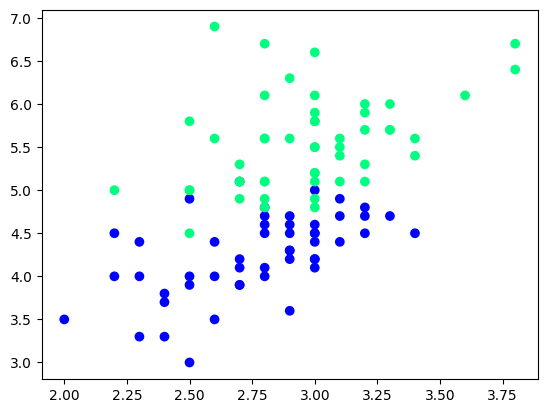

In [92]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')

# Taking only 10 rows for training

In [93]:
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [94]:
df_train.shape,df_val.shape,df_test.shape

((10, 3), (5, 3), (5, 3))

#X_test,y_test

In [95]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

#<font color='red'> Case 1 - Bagging

In [96]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [97]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))


#-----------------------------tree1

     SepalWidthCm  PetalLengthCm  Species
84            3.0            4.5        1
142           2.7            5.1        2
147           3.0            5.2        2
84            3.0            4.5        1
147           3.0            5.2        2
73            2.8            4.7        1
73            2.8            4.7        1
142           2.7            5.1        2


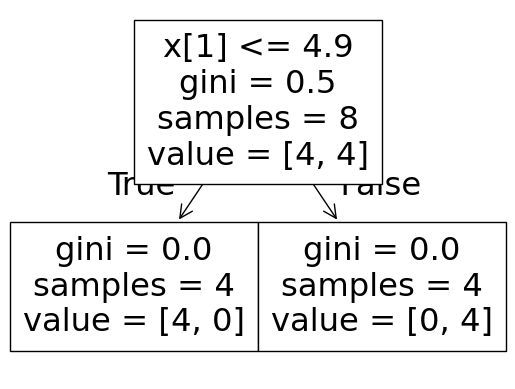

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


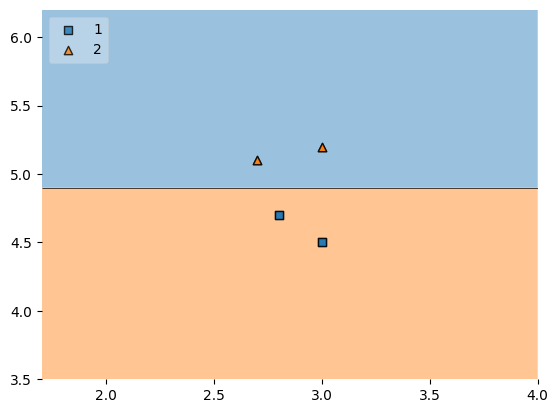

In [117]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]
print(df_bag)
dt_bag1 = DecisionTreeClassifier()
evaluate(dt_bag1,X,y)

#--------------------------------------tree2

     SepalWidthCm  PetalLengthCm  Species
142           2.7            5.1        2
84            3.0            4.5        1
106           2.5            4.5        2
106           2.5            4.5        2
84            3.0            4.5        1
113           2.5            5.0        2
147           3.0            5.2        2
84            3.0            4.5        1


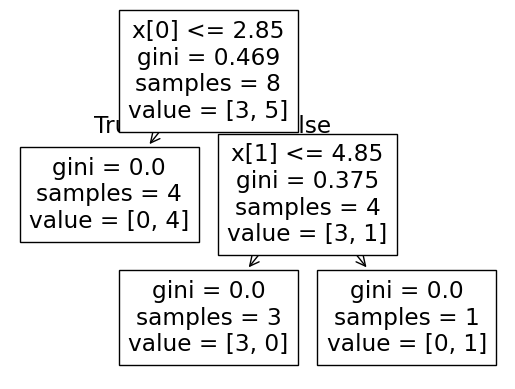

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.6


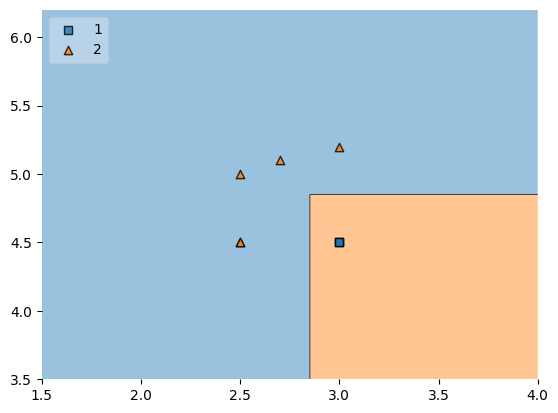

In [118]:
# Data for Tree 2
df_bag = df_train.sample(8,replace=True)
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]
print(df_bag)
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

#----------------------------------------tree3

     SepalWidthCm  PetalLengthCm  Species
113           2.5            5.0        2
108           2.5            5.8        2
113           2.5            5.0        2
106           2.5            4.5        2
91            3.0            4.6        1
58            2.9            4.6        1
147           3.0            5.2        2
134           2.6            5.6        2


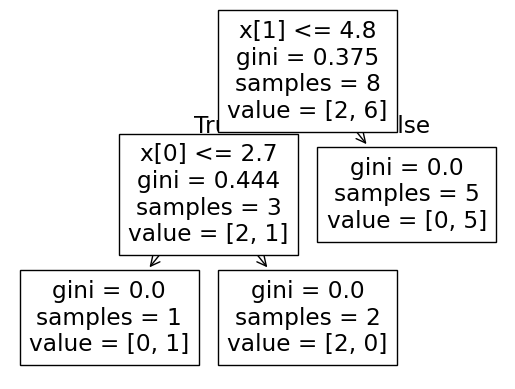

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


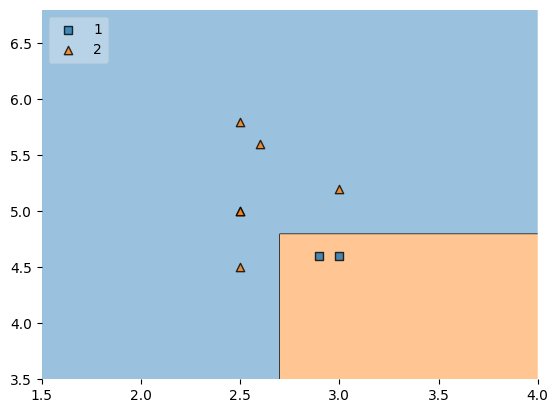

In [120]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]
print(df_bag)
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

## Predict

In [121]:
print(df_test.shape)
df_test

(5, 3)


,SepalWidthCm,PetalLengthCm,Species
85,3.4,4.5,1
53,2.3,4.0,1
146,2.5,5.0,2
125,3.2,6.0,2
56,3.3,4.7,1


In [107]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [2]
Predictor 3 [2]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


#<font color='red'>case 2- Pasting

# Row sampling without replacement

In [108]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
113,2.5,5.0,2
73,2.8,4.7,1
106,2.5,4.5,2
147,3.0,5.2,2
108,2.5,5.8,2
142,2.7,5.1,2
91,3.0,4.6,1
58,2.9,4.6,1
134,2.6,5.6,2
84,3.0,4.5,1


In [109]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
84,3.0,4.5,1
142,2.7,5.1,2
106,2.5,4.5,2
134,2.6,5.6,2
113,2.5,5.0,2
58,2.9,4.6,1
91,3.0,4.6,1
73,2.8,4.7,1


#<font color='red'> case 3 - Random Subspaces

#column wise replacement

In [110]:
df1 = pd.read_csv('/content/Iris.csv')
df1 = df1.sample(10)

In [111]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
103,104,6.3,2.9,5.6,1.8,Iris-virginica
119,120,6.0,2.2,5.0,1.5,Iris-virginica
13,14,4.3,3.0,1.1,0.1,Iris-setosa
74,75,6.4,2.9,4.3,1.3,Iris-versicolor
9,10,4.9,3.1,1.5,0.1,Iris-setosa
36,37,5.5,3.5,1.3,0.2,Iris-setosa
61,62,5.9,3.0,4.2,1.5,Iris-versicolor
85,86,6.0,3.4,4.5,1.6,Iris-versicolor
54,55,6.5,2.8,4.6,1.5,Iris-versicolor
60,61,5.0,2.0,3.5,1.0,Iris-versicolor


In [112]:
df1.sample(2,replace=True,axis=1)

,Species,PetalWidthCm
103,Iris-virginica,1.8
119,Iris-virginica,1.5
13,Iris-setosa,0.1
74,Iris-versicolor,1.3
9,Iris-setosa,0.1
36,Iris-setosa,0.2
61,Iris-versicolor,1.5
85,Iris-versicolor,1.6
54,Iris-versicolor,1.5
60,Iris-versicolor,1.0


#<font color='red'>case 4 Random Patches

In [113]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
103,104,6.3,2.9,5.6,1.8,Iris-virginica
119,120,6.0,2.2,5.0,1.5,Iris-virginica
13,14,4.3,3.0,1.1,0.1,Iris-setosa
74,75,6.4,2.9,4.3,1.3,Iris-versicolor
9,10,4.9,3.1,1.5,0.1,Iris-setosa
36,37,5.5,3.5,1.3,0.2,Iris-setosa
61,62,5.9,3.0,4.2,1.5,Iris-versicolor
85,86,6.0,3.4,4.5,1.6,Iris-versicolor
54,55,6.5,2.8,4.6,1.5,Iris-versicolor
60,61,5.0,2.0,3.5,1.0,Iris-versicolor


In [114]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,SepalWidthCm,SepalWidthCm
36,3.5,3.5
61,3.0,3.0
60,2.0,2.0
36,3.5,3.5
61,3.0,3.0
9,3.1,3.1
54,2.8,2.8
9,3.1,3.1
